# Mini2P line-waveform stripe removal

This notebook targets Mini2P stripe artifacts that are synchronized to the scan lines.

This is different from subtracting the full average line. Instead, for each frame it:

1. separates even and odd lines,
2. estimates the shared fast-axis waveform for each line direction,
3. removes the slow spatial component from that waveform,
4. subtracts only the high-frequency stripe waveform,
5. preserves the frame intensity baseline.

This should remove stripe-like electrical noise while preserving more biological signal than broad detrending.

Assumed raw TIFF shape: `frames x height x width`.

For your file this looked like `(21820, 512, 512)`.

In [1]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

try:
    from scipy.ndimage import gaussian_filter1d
except ImportError:
    raise ImportError("Install scipy first: pip install scipy  or  conda install scipy")

# ----------------------------
# User settings
# ----------------------------
path = "/Users/megyoung/Desktop/mini2p Images/72Lgoodtask"  # CHANGE THIS
selected_tiff = "72ltask_00001.tif"  # CHANGE THIS if needed

tiff_path = os.path.join(path, selected_tiff)

# Which interleaved channel is GCaMP / functional?
# 0 means raw frames 0, 2, 4, ...
# 1 means raw frames 1, 3, 5, ...
signal_channel = 1

# Processing size. Lower if kernel crashes.
chunk_size = 25

base = os.path.splitext(selected_tiff)[0]

In [2]:
# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Raw frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

signal_frames = np.arange(signal_channel, n_pages, 2)
print("Signal frames:", len(signal_frames))

Raw frames: 21820
Height: 512
Width: 512
dtype: int16
Signal frames: 10910


In [3]:
def read_pages_from_open_tif(tif, frame_indices):
    return np.stack([tif.pages[int(i)].asarray() for i in frame_indices], axis=0)


def robust_rescale_for_display(img, low=1, high=99):
    img = img.astype(np.float32)
    vmin, vmax = np.nanpercentile(img, [low, high])
    return np.clip((img - vmin) / (vmax - vmin + 1e-8), 0, 1)


def convert_for_suite2p(chunk, output_dtype=np.uint16):
    if output_dtype == np.uint16:
        return np.clip(chunk, 0, 65535).astype(np.uint16)

    if output_dtype == np.int16:
        info = np.iinfo(np.int16)
        return np.clip(chunk, info.min, info.max).astype(np.int16)

    return chunk.astype(output_dtype)


def preview_interleaved_channel(tiff_path, channel, n_frames=200, start=0):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)
        inds = channel_frames[start:start + n_frames]
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img

In [4]:
def estimate_line_waveforms(
    frame,
    method="median",
    smooth_sigma=20,
    extra_waveform_smoothing=0,
    center_waveform=True,
):
    """
    Estimate high-frequency fast-axis stripe waveforms separately for
    even and odd scan lines.

    frame shape: height x width

    method:
        "median" is more robust to cells/bright structures.
        "mean" may estimate weak stripe signal more strongly.

    smooth_sigma:
        Gaussian sigma along x used to estimate the slow biological/spatial trend.
        Larger values keep broader stripe components.
        Try 5, 10, 20, 40.

    extra_waveform_smoothing:
        Optional small smoothing of the final waveform.
        Usually 0 or 1.

    Returns:
        waveform_even, waveform_odd
    """
    frame = frame.astype(np.float32)

    even_lines = frame[::2, :]
    odd_lines = frame[1::2, :]

    if method == "median":
        avg_even = np.nanmedian(even_lines, axis=0)
        avg_odd = np.nanmedian(odd_lines, axis=0)
    elif method == "mean":
        avg_even = np.nanmean(even_lines, axis=0)
        avg_odd = np.nanmean(odd_lines, axis=0)
    else:
        raise ValueError("method must be 'median' or 'mean'")

    slow_even = gaussian_filter1d(avg_even, sigma=smooth_sigma, mode="nearest")
    slow_odd = gaussian_filter1d(avg_odd, sigma=smooth_sigma, mode="nearest")

    waveform_even = avg_even - slow_even
    waveform_odd = avg_odd - slow_odd

    if extra_waveform_smoothing and extra_waveform_smoothing > 0:
        waveform_even = gaussian_filter1d(waveform_even, sigma=extra_waveform_smoothing, mode="nearest")
        waveform_odd = gaussian_filter1d(waveform_odd, sigma=extra_waveform_smoothing, mode="nearest")

    if center_waveform:
        waveform_even = waveform_even - np.nanmedian(waveform_even)
        waveform_odd = waveform_odd - np.nanmedian(waveform_odd)

    return waveform_even.astype(np.float32), waveform_odd.astype(np.float32)


def correct_frame_line_waveform(
    frame,
    method="median",
    smooth_sigma=20,
    extra_waveform_smoothing=0,
    correction_strength=1.0,
    preserve_baseline=True,
):
    frame = frame.astype(np.float32)

    waveform_even, waveform_odd = estimate_line_waveforms(
        frame,
        method=method,
        smooth_sigma=smooth_sigma,
        extra_waveform_smoothing=extra_waveform_smoothing,
        center_waveform=True,
    )

    corrected = frame.copy()
    corrected[::2, :] = corrected[::2, :] - correction_strength * waveform_even[None, :]
    corrected[1::2, :] = corrected[1::2, :] - correction_strength * waveform_odd[None, :]

    if preserve_baseline:
        corrected = corrected - np.nanmedian(corrected) + np.nanmedian(frame)

    removed = frame - corrected

    return corrected.astype(np.float32), removed.astype(np.float32), waveform_even, waveform_odd


def correct_chunk_line_waveform(
    chunk,
    method="median",
    smooth_sigma=20,
    extra_waveform_smoothing=0,
    correction_strength=1.0,
    preserve_baseline=True,
):
    chunk = chunk.astype(np.float32)

    corrected = np.empty_like(chunk, dtype=np.float32)
    removed = np.empty_like(chunk, dtype=np.float32)
    waveforms_even = []
    waveforms_odd = []

    for i in range(chunk.shape[0]):
        corrected[i], removed[i], we, wo = correct_frame_line_waveform(
            chunk[i],
            method=method,
            smooth_sigma=smooth_sigma,
            extra_waveform_smoothing=extra_waveform_smoothing,
            correction_strength=correction_strength,
            preserve_baseline=preserve_baseline,
        )
        waveforms_even.append(we)
        waveforms_odd.append(wo)

    return corrected, removed, np.stack(waveforms_even), np.stack(waveforms_odd)

## Preview parameter suggestions

Start conservative:

```python
method = "median"
smooth_sigma = 20
correction_strength = 1.0
```

If stripes remain:

```python
smooth_sigma = 40
correction_strength = 1.5
```

If it removes real structure:

```python
smooth_sigma = 10
correction_strength = 0.75
```

Important: the **Removed component** should look like stripes/line-waveform noise, not cells.

In [5]:
# ----------------------------
# Preview parameters
# ----------------------------
method = "median"              # "median" or "mean"
smooth_sigma = 20              # try 5, 10, 20, 40
extra_waveform_smoothing = 0   # try 0 or 1
correction_strength = 1.0      # try 0.75, 1.0, 1.5, 2.0
preserve_baseline = True

preview_start = 0
preview_n_frames = 100

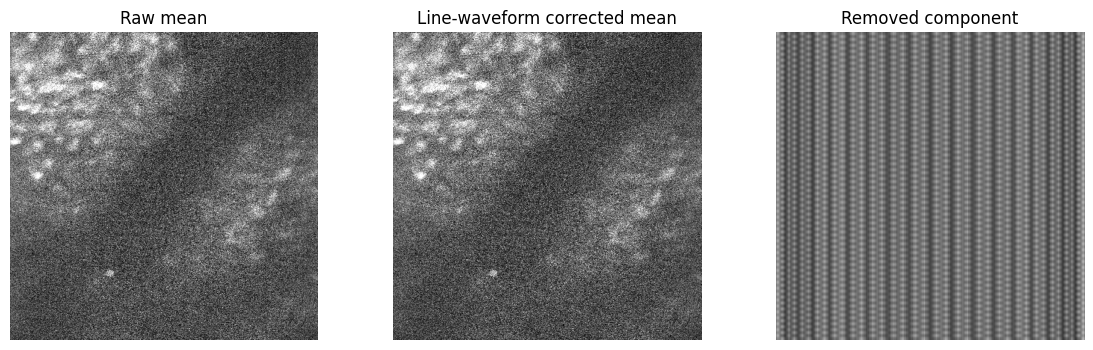

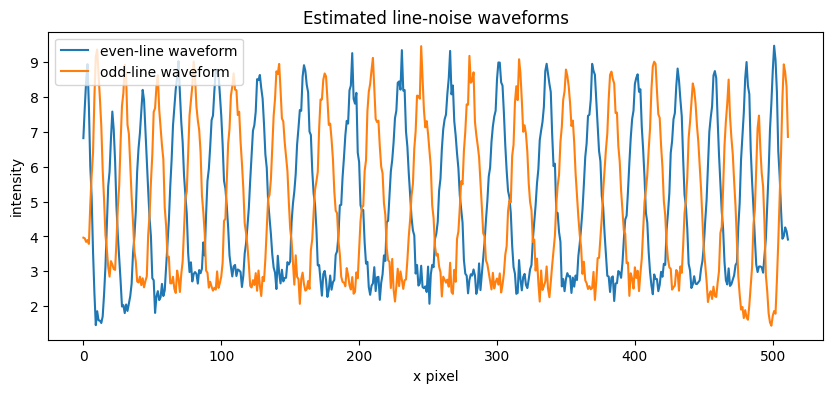

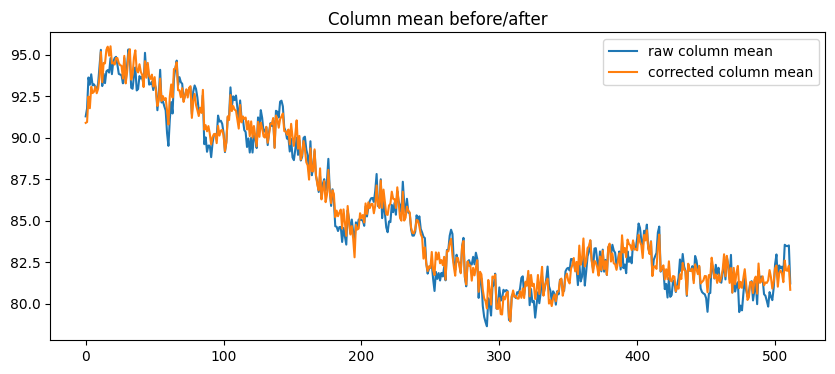

Raw mean range: [ 51.54999924  83.44000244 140.24000549]
Corrected mean range: [ 52.036875    83.50623703 140.06802963]
Removed mean range: [-3.27501583 -0.55690813  4.07117987]


13422

In [6]:
# ----------------------------
# Preview correction on a small chunk
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    signal_frames = np.arange(signal_channel, n_pages, 2)

    preview_inds = signal_frames[preview_start:preview_start + preview_n_frames]
    preview_chunk = read_pages_from_open_tif(tif, preview_inds).astype(np.float32)

corrected_chunk, removed_chunk, waveforms_even, waveforms_odd = correct_chunk_line_waveform(
    preview_chunk,
    method=method,
    smooth_sigma=smooth_sigma,
    extra_waveform_smoothing=extra_waveform_smoothing,
    correction_strength=correction_strength,
    preserve_baseline=preserve_baseline,
)

raw_mean = np.mean(preview_chunk, axis=0)
corrected_mean = np.mean(corrected_chunk, axis=0)
removed_mean = np.mean(removed_chunk, axis=0)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_mean), cmap="gray")
plt.title("Raw mean")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(corrected_mean), cmap="gray")
plt.title("Line-waveform corrected mean")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(removed_mean), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

plt.figure(figsize=(10, 4))
plt.plot(np.mean(waveforms_even, axis=0), label="even-line waveform")
plt.plot(np.mean(waveforms_odd, axis=0), label="odd-line waveform")
plt.legend()
plt.title("Estimated line-noise waveforms")
plt.xlabel("x pixel")
plt.ylabel("intensity")
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(np.mean(raw_mean, axis=0), label="raw column mean")
plt.plot(np.mean(corrected_mean, axis=0), label="corrected column mean")
plt.legend()
plt.title("Column mean before/after")
plt.show()

print("Raw mean range:", np.percentile(raw_mean, [1, 50, 99]))
print("Corrected mean range:", np.percentile(corrected_mean, [1, 50, 99]))
print("Removed mean range:", np.percentile(removed_mean, [1, 50, 99]))

del preview_chunk, corrected_chunk, removed_chunk
gc.collect()

In [7]:
def run_line_waveform_correction(
    tiff_path,
    signal_channel,
    output_file,
    chunk_size=25,
    method="median",
    smooth_sigma=20,
    extra_waveform_smoothing=0,
    correction_strength=1.0,
    preserve_baseline=True,
    output_dtype=np.uint16,
):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        signal_frames = np.arange(signal_channel, n_pages, 2)
        n = len(signal_frames)

        print("Frames to process:", n)
        print("Saving to:", output_file)

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, n, chunk_size):
                end = min(start + chunk_size, n)
                inds = signal_frames[start:end]

                chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

                corrected, removed, waveforms_even, waveforms_odd = correct_chunk_line_waveform(
                    chunk,
                    method=method,
                    smooth_sigma=smooth_sigma,
                    extra_waveform_smoothing=extra_waveform_smoothing,
                    correction_strength=correction_strength,
                    preserve_baseline=preserve_baseline,
                )

                corrected_to_save = convert_for_suite2p(corrected, output_dtype=output_dtype)
                writer.write(corrected_to_save, photometric="minisblack")

                print(f"Saved frames {start} to {end} / {n}")

                del chunk, corrected, corrected_to_save, removed, waveforms_even, waveforms_odd
                gc.collect()

    print("Done:", output_file)

In [8]:
# ----------------------------
# Run full correction and save new TIFF
# ----------------------------
output_file = os.path.join(
    path,
    f"{base}_unstriped_linewave_ch{signal_channel}_sigma{smooth_sigma}_strength{correction_strength}.tiff"
)

run_line_waveform_correction(
    tiff_path=tiff_path,
    signal_channel=signal_channel,
    output_file=output_file,
    chunk_size=chunk_size,
    method=method,
    smooth_sigma=smooth_sigma,
    extra_waveform_smoothing=extra_waveform_smoothing,
    correction_strength=correction_strength,
    preserve_baseline=preserve_baseline,
    output_dtype=np.uint16,
)

Frames to process: 10910
Saving to: /Users/megyoung/Desktop/mini2p Images/72Lgoodtask/72ltask_00001_unstriped_linewave_ch1_sigma20_strength1.0.tiff
Saved frames 0 to 25 / 10910
Saved frames 25 to 50 / 10910
Saved frames 50 to 75 / 10910
Saved frames 75 to 100 / 10910
Saved frames 100 to 125 / 10910
Saved frames 125 to 150 / 10910
Saved frames 150 to 175 / 10910
Saved frames 175 to 200 / 10910
Saved frames 200 to 225 / 10910
Saved frames 225 to 250 / 10910
Saved frames 250 to 275 / 10910
Saved frames 275 to 300 / 10910
Saved frames 300 to 325 / 10910
Saved frames 325 to 350 / 10910
Saved frames 350 to 375 / 10910
Saved frames 375 to 400 / 10910
Saved frames 400 to 425 / 10910
Saved frames 425 to 450 / 10910
Saved frames 450 to 475 / 10910
Saved frames 475 to 500 / 10910
Saved frames 500 to 525 / 10910
Saved frames 525 to 550 / 10910
Saved frames 550 to 575 / 10910
Saved frames 575 to 600 / 10910
Saved frames 600 to 625 / 10910
Saved frames 625 to 650 / 10910
Saved frames 650 to 675 / 10

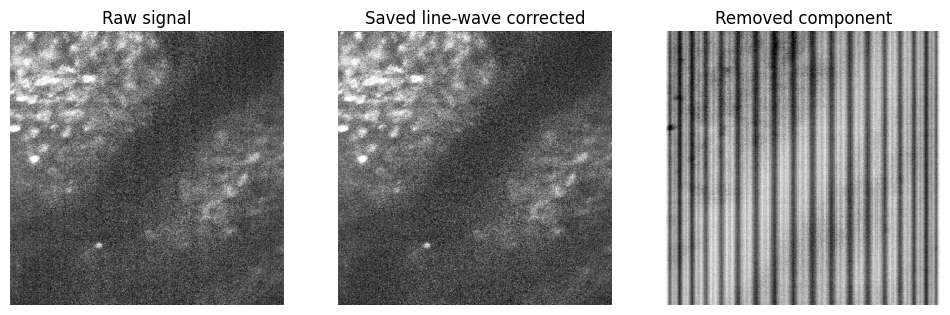

Saved corrected TIFF:
/Users/megyoung/Desktop/mini2p Images/72Lgoodtask/72ltask_00001_unstriped_linewave_ch1_sigma20_strength1.0.tiff


In [9]:
# ----------------------------
# Preview saved output
# ----------------------------
def preview_saved_tiff(tiff_path, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(0, min(n_pages, n_frames))
        chunk = read_pages_from_open_tif(tif, inds).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)
    del chunk
    gc.collect()
    return mean_img


saved_preview = preview_saved_tiff(output_file, n_frames=200)
raw_preview = preview_interleaved_channel(tiff_path, signal_channel, n_frames=200)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(robust_rescale_for_display(raw_preview), cmap="gray")
plt.title("Raw signal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(robust_rescale_for_display(saved_preview), cmap="gray")
plt.title("Saved line-wave corrected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(robust_rescale_for_display(raw_preview - saved_preview), cmap="gray")
plt.title("Removed component")
plt.axis("off")

plt.show()

print("Saved corrected TIFF:")
print(output_file)